# <center>**Persona Based Information Retrieval**</center>
#### Lorenzo Tripepi - Communication Leader - 513176
#### Pietro Scapini - 513351
#### Vincenzo Perazzoli - 512994

# **DATA LOADING and CLEANING**

In [1]:
!pip install ir_datasets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 947.8/947.8 kB 54.2 MB/s eta 0:00:00


In [2]:
import ir_datasets
import pandas as pd

dataset = ir_datasets.load("antique/test")

## LOADING *queries* DATAFRAME

In [3]:
query_list = [{"query_id": q.query_id, "text": q.text} for q in dataset.queries_iter()]

df_queries = pd.DataFrame(query_list)

df_queries.head()

[INFO] Please confirm you agree to the authors' data usage agreement found at <https://ciir.cs.umass.edu/downloads/Antique/readme.txt>
[INFO] [starting] https://ciir.cs.umass.edu/downloads/Antique/antique-test-queries.txt
[INFO] [finished] https://ciir.cs.umass.edu/downloads/Antique/antique-test-queries.txt: [00:00] [11.4kB] [49.4kB/s]


,query_id,text
0,3990512,how can we get concentration onsomething?
1,714612,Why doesn't the water fall off earth if it's ...
2,2528767,How do I determine the charge of the iron ion ...
3,821387,I have mice.How do I get rid of them humanely?
4,1880028,"What does ""see Leaflet"" mean on Ept Pregnancy ..."


In [ ]:
df_queries.shape

(200, 2)

##  LOADING *docs* DATAFRAME

In [4]:
doc_list = [{"doc_id": q.doc_id, "text": q.text} for q in dataset.docs_iter()]

df_doc = pd.DataFrame(doc_list)

df_doc.head()

[INFO] If you have a local copy of https://ciir.cs.umass.edu/downloads/Antique/antique-collection.txt, you can symlink it here to avoid downloading it again: /root/.ir_datasets/downloads/684f7015aff377062a758e478476aac8
[INFO] [starting] https://ciir.cs.umass.edu/downloads/Antique/antique-collection.txt
[INFO] [finished] https://ciir.cs.umass.edu/downloads/Antique/antique-collection.txt: [00:08] [93.6MB] [11.0MB/s]


,doc_id,text
0,2020338_0,A small group of politicians believed strongly...
1,2020338_1,Because there is a lot of oil in Iraq.
2,2020338_2,It is tempting to say that the US invaded Iraq...
3,2020338_3,I think Yuval is pretty spot on. It's a provin...
4,2874684_0,Call an area apiarist. They should be able to...


In [5]:
df_doc.shape

(403666, 2)

##  LOADING *qrels* DATAFRAME

In [6]:
qrels_list = [{
    "query_id": qrel.query_id,
    "doc_id": qrel.doc_id,
    "relevance": qrel.relevance,
    "iteration": qrel.iteration
} for qrel in dataset.qrels_iter()]

df_qrels = pd.DataFrame(qrels_list)

df_qrels.head()

[INFO] [starting] https://ciir.cs.umass.edu/downloads/Antique/antique-test.qrel
[INFO] [finished] https://ciir.cs.umass.edu/downloads/Antique/antique-test.qrel: [00:00] [150kB] [213kB/s]


,query_id,doc_id,relevance,iteration
0,1964316,1964316_5,4,U0
1,1964316,1674088_11,1,Q0
2,1964316,1218838_13,2,Q0
3,1964316,1519022_15,2,Q0
4,1964316,3059341_5,2,Q0


In [7]:
df_qrels.shape

(6589, 4)

The 'iteration' column is removed, and the 'relevance' column is converted to a binary format by mapping values 1 and 2 to 0, and all other values to 1.

In [8]:
df_qrels_binary = df_qrels.copy()

In [9]:
df_qrels_binary = df_qrels_binary.drop(columns=['iteration'])
df_qrels_binary['relevance'] = df_qrels_binary['relevance'].apply(lambda x: 0 if x in [1, 2] else 1)
df_qrels_binary.head()

,query_id,doc_id,relevance
0,1964316,1964316_5,1
1,1964316,1674088_11,0
2,1964316,1218838_13,0
3,1964316,1519022_15,0
4,1964316,3059341_5,0


In [11]:
df_doc_final = df_doc.copy()

# **EXPLORATIVE DATA ANALYSIS**

## QUERY RESPONSE DISTRIBUTION in *df_qrels*

This code counts how many responses in *df_qrels* each query has and plots a bar chart showing the distribution of the number of responses per query.

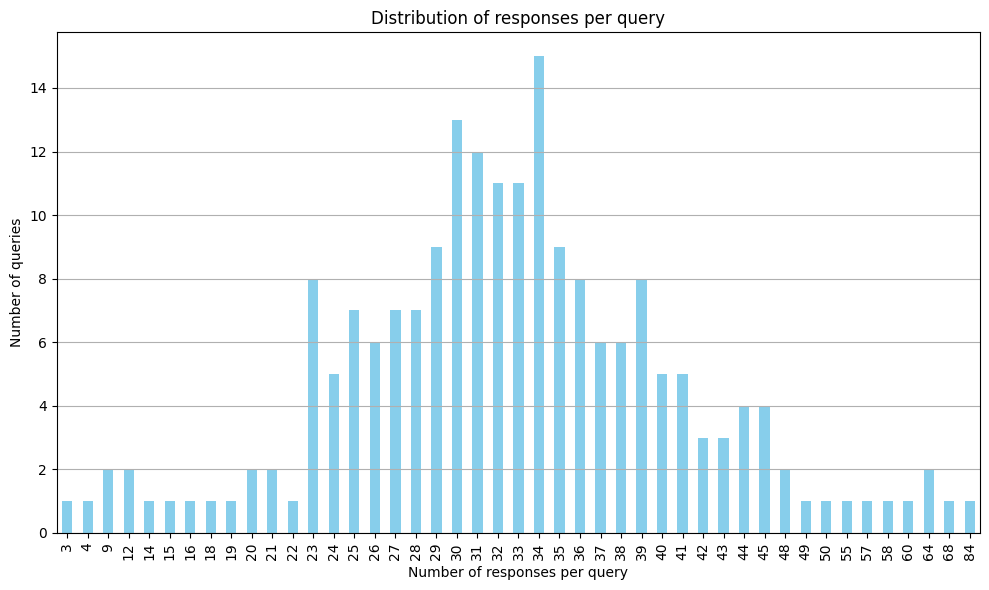

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

counts = df_qrels['query_id'].value_counts().sort_index()

plt.figure(figsize=(10,6))
counts.value_counts().sort_index().plot(kind='bar', color='skyblue')  # colore azzurro
plt.xlabel("Number of responses per query")
plt.ylabel("Number of queries")
plt.title("Distribution of responses per query")
plt.grid(axis='y')
plt.tight_layout()
plt.savefig("query response distribution.jpg", dpi=1000)
plt.show()


Here, we identify and print the queries with the highest and lowest number of responses along with their counts.

In [13]:
max_query = counts.idxmax()
max_count = counts.max()

min_query = counts.idxmin()
min_count = counts.min()

print(f"🔺 Query with the most responses: {max_query} ({max_count} responses)")
print(f"🔻 Query with the fewest responses: {min_query} ({min_count} responses)")

🔺 Query with the most responses: 4018891 (84 responses)
🔻 Query with the fewest responses: 78762 (3 responses)


In [14]:
query_text = df_queries.loc[df_queries['query_id'] == max_query, 'text'].values
print(query_text)

['How do I know if a particular term or phrase is copyrighted?']


## DISTRIBUTION OF RESPONSE LENGTHS (IN WORDS)

This code calculates the length of each response in words and plots a histogram with a KDE curve to show the distribution of response lengths.

Text(0, 0.5, 'Frequency')

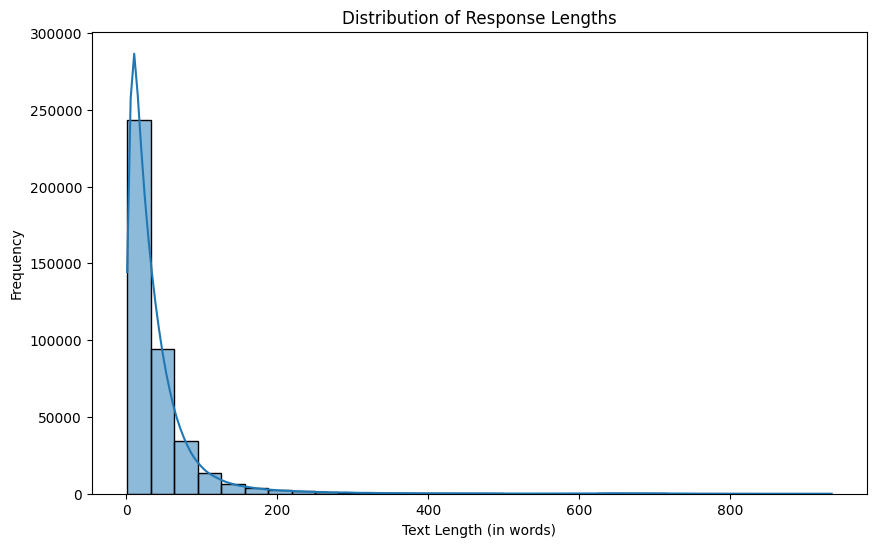

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

df_doc_exploration = df_doc_final.copy()

df_doc_exploration['text_length'] = df_doc_exploration['text'].str.split().str.len()  # in words

plt.figure(figsize=(10, 6))
sns.histplot(df_doc_exploration['text_length'], bins=30, kde=True)

plt.title('Distribution of Response Lengths')
plt.xlabel('Text Length (in words)')
plt.ylabel('Frequency')

Here we calculate the minimum and maximum response lengths (in words), counts how many responses have those lengths, and prints the results.

In [16]:
min_len = df_doc_exploration['text_length'].min()
max_len = df_doc_exploration['text_length'].max()

num_min = (df_doc_exploration['text_length'] == min_len).sum()
num_max = (df_doc_exploration['text_length'] == max_len).sum()

print(f"Minimum length (in words): {min_len} -> {num_min} responses")
print(f"Maximum length (in words): {max_len} -> {num_max} responses")

Minimum length (in words): 1 -> 6117 responses
Maximum length (in words): 935 -> 1 responses


In [17]:
df_one_length= df_doc_exploration[df_doc_exploration['text_length'] == 1]
print(df_one_length['text'])

141          www.skype.com
253       http://info.com/
561                   jhgd
789                  bored
833            Impossible.
                ...       
403365         MOTIVATION!
403418            Claritin
403521            death...
403609          ship/ferry
403613                 bus
Name: text, Length: 6117, dtype: object


## DISTRIBUTION OF QUERY LENGTHS (IN WORDS)

This code calculates the length of each query in words and plots a histogram with a KDE curve to show the distribution of query lengths.

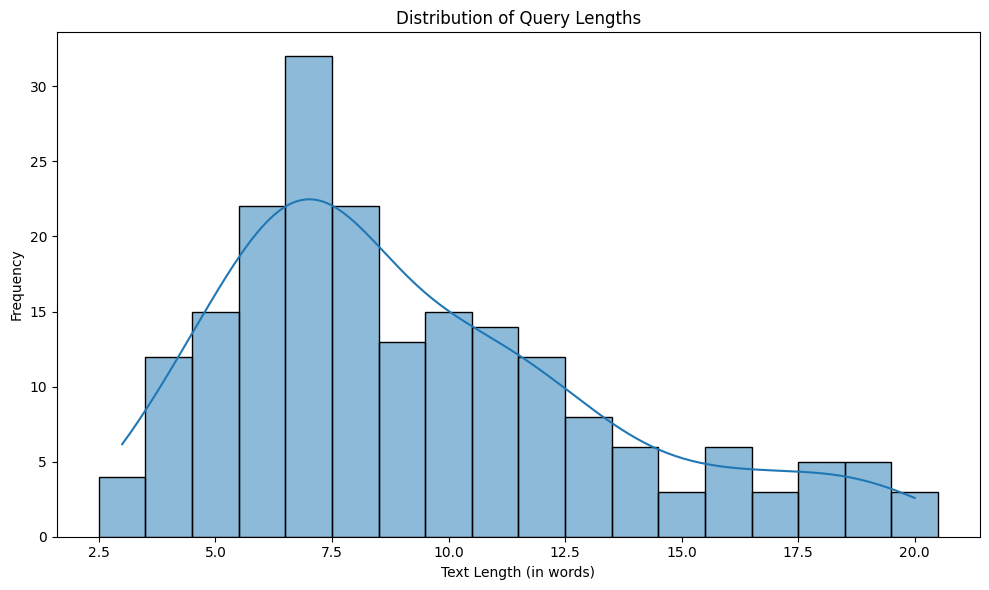

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

df_queries_exploration = df_queries.copy()

df_queries_exploration['text_length'] = df_queries_exploration['text'].str.split().str.len()  # in parole

plt.figure(figsize=(10, 6))
bins = range(df_queries_exploration['text_length'].min(), df_queries_exploration['text_length'].max() + 1)
sns.histplot(df_queries_exploration['text_length'], bins=bins, kde=True, discrete=True)

plt.title('Distribution of Query Lengths')
plt.xlabel('Text Length (in words)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


Here we calculate the minimum and maximum query lengths (in words), counts how many responses have those lengths, and prints the results.

In [19]:
min_len = df_queries_exploration['text_length'].min()
max_len = df_queries_exploration['text_length'].max()

num_min = (df_queries_exploration['text_length'] == min_len).sum()
num_max = (df_queries_exploration['text_length'] == max_len).sum()

print(f"Minimum length (in words): {min_len} -> {num_min} queries")
print(f"Maximum length (in words): {max_len} -> {num_max} queries")

Minimum length (in words): 3 -> 4 queries
Maximum length (in words): 20 -> 3 queries


In [20]:
df_one_length_queries = df_queries_exploration[df_queries_exploration['text_length'] == 3]
print(df_one_length_queries['text'])

9         What is Blaphsemy?
96         what are mormens?
136     what is citriscidal?
199    what is masturbat***?
Name: text, dtype: object


## TOP WORD FREQUENCY IN RESPONSES (EXCLUDING STOP WORDS)

In [21]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from collections import Counter
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import nltk


nltk.download('punkt')
nltk.download('stopwords')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

This code concatenates all response texts, tokenizes and cleans them by removing punctuation and stopwords, then counts and prints the 20 most frequent words.

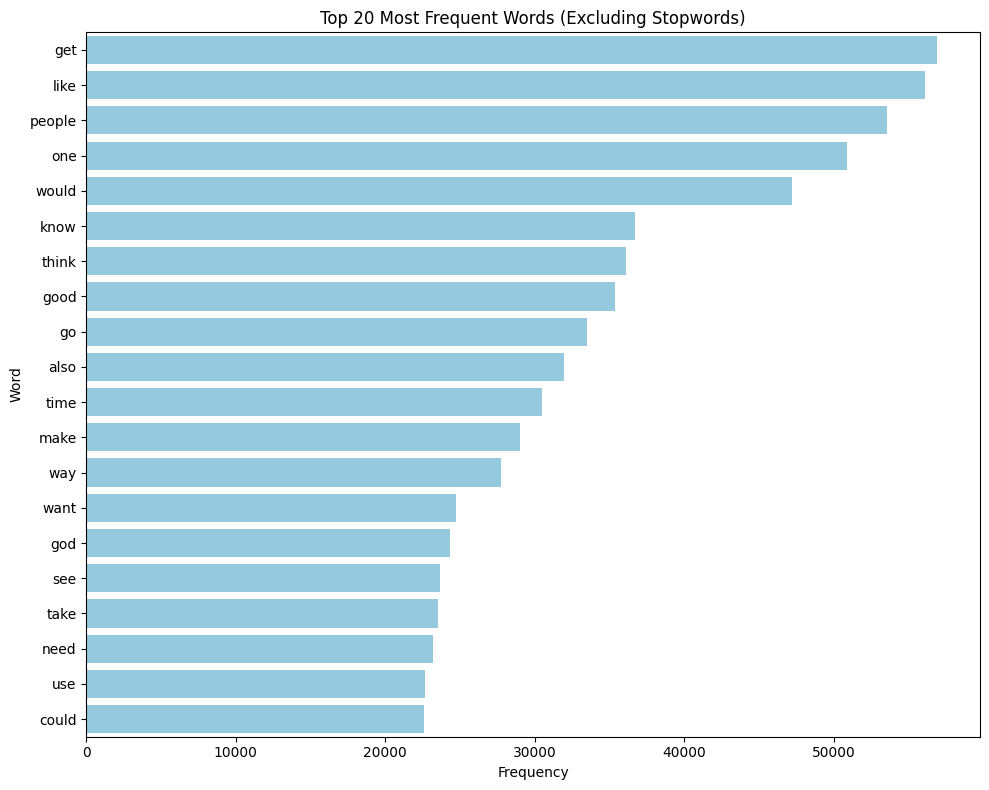

In [22]:
all_text = ' '.join(df_doc_final['text'].astype(str))

tokens = word_tokenize(all_text.lower())
stop_words = set(stopwords.words('english'))
tokens_cleaned = [word for word in tokens if word.isalpha() and word not in stop_words]

word_freq = Counter(tokens_cleaned)
top_words = word_freq.most_common(20)

words, freqs = zip(*top_words)

plt.figure(figsize=(10, 8))
sns.barplot(x=list(freqs), y=list(words), color='skyblue')
plt.xlabel('Frequency')
plt.ylabel('Word')
plt.title('Top 20 Most Frequent Words (Excluding Stopwords)')
plt.tight_layout()

plt.show()


## TOP WORD FREQUENCY IN QUERIES (EXCLUDING STOP WORDS)

This code concatenates all query texts, tokenizes and cleans them by removing punctuation and stopwords, then counts and prints the 20 most frequent words.

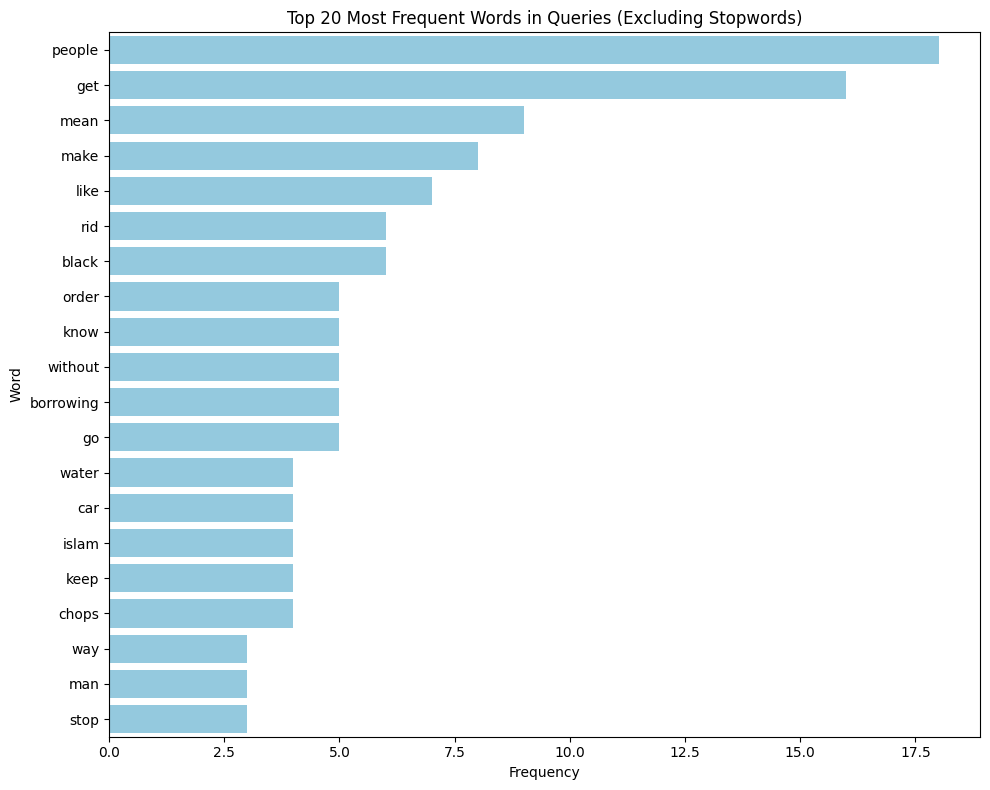

In [23]:
all_text = ' '.join(df_queries['text'].astype(str))

tokens = word_tokenize(all_text.lower())
stop_words = set(stopwords.words('english'))
tokens_cleaned = [word for word in tokens if word.isalpha() and word not in stop_words]

word_freq = Counter(tokens_cleaned)
top_words = word_freq.most_common(20)

words, freqs = zip(*top_words)
plt.figure(figsize=(10, 8))
sns.barplot(x=list(freqs), y=list(words), color='skyblue')
plt.xlabel('Frequency')
plt.ylabel('Word')
plt.title('Top 20 Most Frequent Words in Queries (Excluding Stopwords)')
plt.tight_layout()
plt.show()

# **PHASE I**

## BASELINE RETRIEVAL (BM25)

BM25 is a probabilistic ranking model that measures the relevance of a document D with respect to a query Q.

- Takes into account the frequency of the term in the document

- Normalizes for the length of the document

- Uses an IDF weight to penalize terms that are too common

In [24]:
!pip install rank_bm25
import nltk
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [25]:
df_doc_bm25 = df_doc_final.copy()
df_doc_bm25 = df_doc_bm25.rename(columns={'text': 'text_tokenization'})

df_queries_bm25 = df_queries.copy()
df_queries_bm25 = df_queries_bm25.rename(columns={'text': 'text_tokenization'})

In [30]:
import pandas as pd
from rank_bm25 import BM25Okapi
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from sklearn.preprocessing import MinMaxScaler
import numpy as np


def generate_bm25(df_doc, df_queries, top_k=10):

    def tokenization(text):
        stop_words = set(stopwords.words('english'))
        tokens = word_tokenize(text.lower())
        return [
            token for token in tokens
            if token.isalnum() and token not in stop_words
        ]

    # Tokenize without overwriting the text in the dataframe.
    corpus = df_doc['text_tokenization'].apply(tokenization).tolist()
    bm25 = BM25Okapi(corpus)

    doc_ids = df_doc['doc_id'].tolist()
    results_query = []

    for _, row in df_queries.iterrows():
        query_text = row['text_tokenization']
        query_tokens = tokenization(query_text)

        # Compute the scores without using the qrels.
        scores = bm25.get_scores(query_tokens)

        # Keep the normalization already present in the original code.
        scores_norm = MinMaxScaler().fit_transform(
            np.array(scores).reshape(-1, 1)
        ).flatten()

        scored_docs = list(zip(doc_ids, scores_norm))

        # Use a fixed number of results, independent of relevance.
        top_n = sorted(
            scored_docs,
            key=lambda x: x[1],
            reverse=True
        )[:top_k]

        results_query.append(top_n)

    df_queries['Top_BM25_Relevant'] = results_query

    return df_queries

In [31]:
generate_bm25(df_doc_bm25, df_queries_bm25)

,query_id,text_tokenization,Top_BM25_Relevant
0,3990512,how can we get concentration onsomething?,"[(3149758_0, 1.0), (1772359_2, 0.9875262676296..."
1,714612,Why doesn't the water fall off earth if it's ...,"[(714612_0, 1.0), (714612_7, 0.828061735037150..."
2,2528767,How do I determine the charge of the iron ion ...,"[(2528767_0, 1.0), (2528767_3, 0.7896327568154..."
3,821387,I have mice.How do I get rid of them humanely?,"[(3062044_6, 1.0), (821387_7, 0.84825684544030..."
4,1880028,"What does ""see Leaflet"" mean on Ept Pregnancy ...","[(1426716_0, 1.0), (2266582_1, 0.9229037370461..."
...,...,...,...
195,2192891,how are braces put on and do they hurt a lot?,"[(1900884_3, 1.0), (2322656_3, 0.9226312973389..."
196,4406669,What do you order at Taco Bell?,"[(4406669_4, 1.0), (4430763_1, 0.9830566865054..."
197,1582877,why do we go to school if in the real world we...,"[(1582877_4, 1.0), (1631281_9, 0.9135331451117..."
198,1340574,Why do some people only go to church on Easter...,"[(1340574_2, 1.0), (1340574_3, 0.9017050703363..."


## NEURAL RERANKING

This technique reorders initially retrieved documents using a neural model to improve relevance.

- A bi-encoder encodes queries and documents separately into dense vectors.
- Cosine similarity between embeddings estimates semantic relevance.
- It captures deeper meanings and context beyond exact term matching.


In [ ]:
%pip install -U transformers


In [36]:
df_doc_biencoder = df_doc_final.copy()
df_queries_biencoder = df_queries.copy()

In [41]:
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from tqdm import tqdm
from transformers import AutoTokenizer, AutoModel

tokenizer = AutoTokenizer.from_pretrained('sentence-transformers/all-MiniLM-L6-v2')
model = AutoModel.from_pretrained('sentence-transformers/all-MiniLM-L6-v2')
model.eval()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# Mean Pooling to get sentence embeddings
def mean_pooling(model_output, attention_mask):
    token_embeddings = model_output[0]
    input_mask_expanded = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()
    return torch.sum(token_embeddings * input_mask_expanded, dim=1) / torch.clamp(input_mask_expanded.sum(1), min=1e-9)

# Batched encoding function
def get_embeddings(texts, batch_size=128):
    embeddings = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i+batch_size]
        encoded_input = tokenizer(batch, padding=True, truncation=True, return_tensors='pt').to(device)
        with torch.no_grad():
            model_output = model(**encoded_input)
        sentence_embeddings = mean_pooling(model_output, encoded_input['attention_mask'])
        sentence_embeddings = F.normalize(sentence_embeddings, p=2, dim=1)
        embeddings.append(sentence_embeddings.cpu())
    return torch.cat(embeddings, dim=0)

def generate_biencoder(df_doc, df_queries, k=10):

    df_doc = df_doc.copy()

    # Encode all documents once
    doc_ids = df_doc['doc_id'].tolist()
    doc_texts = df_doc['text'].fillna("").astype(str).tolist()
    doc_embeddings = get_embeddings(doc_texts)

    top_documents = []

    for i in tqdm(range(len(df_queries)), desc="Ranking top 10 documents globally per query"):
        query_id = df_queries.loc[i, 'query_id']
        query_text = df_queries.loc[i, 'text']

        # Encode the query
        query_embedding = get_embeddings([query_text])

        # Compute similarity with all document embeddings
        similarities = F.cosine_similarity(query_embedding, doc_embeddings).numpy()
        top_k_indices = np.argsort(similarities)[::-1][:k]

        # Get top-k (doc_id, score) pairs
        results = [(doc_ids[idx], similarities[idx]) for idx in top_k_indices]
        top_documents.append(results)

    df_queries['Top10_Biencoder'] = top_documents
    return df_queries

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [42]:
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from tqdm import tqdm
from transformers import AutoTokenizer, AutoModel

tokenizer = AutoTokenizer.from_pretrained('sentence-transformers/all-MiniLM-L6-v2')
model = AutoModel.from_pretrained('sentence-transformers/all-MiniLM-L6-v2')
model.eval()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

print("Device:", device)

# Mean Pooling to get sentence embeddings
def mean_pooling(model_output, attention_mask):
    token_embeddings = model_output[0]
    input_mask_expanded = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()
    return torch.sum(token_embeddings * input_mask_expanded, dim=1) / torch.clamp(input_mask_expanded.sum(1), min=1e-9)

# Batched encoding function
def get_embeddings(texts, batch_size=128):
    embeddings = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i+batch_size]
        encoded_input = tokenizer(batch, padding=True, truncation=True, return_tensors='pt').to(device)
        with torch.no_grad():
            model_output = model(**encoded_input)
        sentence_embeddings = mean_pooling(model_output, encoded_input['attention_mask'])
        sentence_embeddings = F.normalize(sentence_embeddings, p=2, dim=1)
        embeddings.append(sentence_embeddings.cpu())
    return torch.cat(embeddings, dim=0)

def generate_biencoder(df_doc, df_queries, k=10):

    df_doc = df_doc.copy()

    print("Number of documents:", len(df_doc))
    print("Number of queries:", len(df_queries))

    # Encode all documents once
    doc_ids = df_doc['doc_id'].tolist()
    doc_texts = df_doc['text'].fillna("").astype(str).tolist()

    print("Starting document encoding...")

    doc_embeddings = get_embeddings(doc_texts)

    print("Document encoding completed.")
    print("Document embeddings shape:", doc_embeddings.shape)

    top_documents = []

    print("Starting query ranking...")

    for i in tqdm(range(len(df_queries)), desc="Ranking top 10 documents globally per query"):
        query_id = df_queries.loc[i, 'query_id']
        query_text = df_queries.loc[i, 'text']

        # Encode the query
        query_embedding = get_embeddings([query_text])

        # Compute similarity with all document embeddings
        similarities = F.cosine_similarity(query_embedding, doc_embeddings).numpy()
        top_k_indices = np.argsort(similarities)[::-1][:k]

        # Get top-k (doc_id, score) pairs
        results = [(doc_ids[idx], similarities[idx]) for idx in top_k_indices]
        top_documents.append(results)

    df_queries['Top10_Biencoder'] = top_documents

    print("Biencoder completed successfully.")

    return df_queries

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Device: cuda


In [43]:
generate_biencoder(df_doc_biencoder, df_queries_biencoder)

Number of documents: 403666
Number of queries: 200
Starting document encoding...
Document encoding completed.
Document embeddings shape: torch.Size([403666, 384])
Starting query ranking...


Ranking top 10 documents globally per query: 100%|██████████| 200/200 [04:14<00:00,  1.27s/it]

Biencoder completed successfully.


,query_id,text,Top10_Biencoder
0,3990512,how can we get concentration onsomething?,"[(3990512_1, 0.74381673), (311770_2, 0.7290008..."
1,714612,Why doesn't the water fall off earth if it's ...,"[(714612_0, 0.8694362), (714612_7, 0.76543504)..."
2,2528767,How do I determine the charge of the iron ion ...,"[(2528767_0, 0.75448424), (2528767_3, 0.750490..."
3,821387,I have mice.How do I get rid of them humanely?,"[(821387_9, 0.78162205), (1082990_5, 0.7802908..."
4,1880028,"What does ""see Leaflet"" mean on Ept Pregnancy ...","[(1880028_0, 0.59638137), (1880028_3, 0.541468..."
...,...,...,...
195,2192891,how are braces put on and do they hurt a lot?,"[(655285_1, 0.73866606), (2192891_1, 0.7368991..."
196,4406669,What do you order at Taco Bell?,"[(4406669_4, 0.81674945), (3438374_10, 0.78887..."
197,1582877,why do we go to school if in the real world we...,"[(1582877_16, 0.7519833), (1582877_14, 0.68016..."
198,1340574,Why do some people only go to church on Easter...,"[(1340574_3, 0.8070097), (1340574_13, 0.763771..."


## FUNCTIONS SECTION: EVALUATION METRICS

### PRECISION and RECALL

**Precision**

This metric measures the proportion of retrieved documents that are actually relevant.

- It focuses on the quality of the top results returned by the system.
- A high precision means few irrelevant documents were retrieved.
- It does not consider how many relevant documents were missed.
- The value ranges from 0 to 1, where 1 means all retrieved documents are relevant.

---

**Recall**

This metric measures the proportion of all relevant documents that were successfully retrieved.

- It evaluates how completely the system finds the relevant information.
- A high recall means most or all relevant documents were retrieved.
- It does not penalize the inclusion of irrelevant documents.
- The value ranges from 0 to 1, where 1 means all relevant documents were retrieved.


In [54]:
def compute_precision_recall_at_k(df_queries, df_qrels, column_ranking, k=5):
    precisions = []
    recalls = []

    for _, row in df_queries.iterrows():
        query_id = row['query_id']

        ranked_docs = [doc_id for doc_id, _ in row[column_ranking]][:k]

        relevant_docs = set(
            df_qrels[
                (df_qrels['query_id'] == query_id) &
                (df_qrels['relevance'] == 1)
            ]['doc_id']
        )

        hits = sum(1 for doc_id in ranked_docs if doc_id in relevant_docs)

        precision = hits / k

        recall = hits / len(relevant_docs) if relevant_docs else 0.0

        precisions.append(precision)
        recalls.append(recall)

    avg_precision = np.mean(precisions) if precisions else 0.0
    avg_recall = np.mean(recalls) if recalls else 0.0

    return avg_precision, avg_recall

In [55]:
def plot_precision_recall(my_dataframe, df_qrels_clean, BM25_or_biencoder_column, k=10):

    ks = list(range(1, k + 1))
    precs = []
    recs  = []
    for i in ks:
        p, r = compute_precision_recall_at_k(my_dataframe, df_qrels_clean, BM25_or_biencoder_column, k=i)
        precs.append(p)
        recs.append(r)

    plt.figure(figsize=(8, 4))
    plt.plot(ks, precs, marker='o', label='Precision')
    plt.plot(ks, recs,  marker='s', label='Recall')
    plt.xlabel('k (number of retrieved documents)')
    plt.ylabel('Average score')
    plt.title('Precision and Recall trends as k varies')
    plt.xticks(ks)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

### MAP

This metric measures the overall precision of a ranking system across multiple queries.

- It calculates the average precision for each query individually.
- It considers the order of relevant documents, rewarding those retrieved earlier.
- The final score is the mean of all average precisions, providing a single effectiveness value.
- The value ranges from 0 to 1, where 1 indicates that all relevant documents are ranked at the top for every query.


In [56]:
def compute_map_at_k(df_queries, df_qrels, column_ranking, k=5):
    average_precisions = []

    for _, row in df_queries.iterrows():
        query_id = row['query_id']

        ranked_docs = [doc_id for doc_id, _ in row[column_ranking]][:k]

        relevant_docs = set(
            df_qrels[
                (df_qrels['query_id'] == query_id) &
                (df_qrels['relevance'] == 1)
            ]['doc_id']
        )

        num_hits = 0
        precision_sum = 0.0

        for i, doc_id in enumerate(ranked_docs, start=1):
            if doc_id in relevant_docs:
                num_hits += 1
                precision_sum += num_hits / i

        if relevant_docs:
            ap = precision_sum / len(relevant_docs)
        else:
            ap = 0.0

        average_precisions.append(ap)

    return np.mean(average_precisions) if average_precisions else 0.0

In [57]:
def plot_map_curve_iterative(df_queries, df_qrels, column_ranking, k_max=5):
    ks = list(range(1, k_max + 1))
    map_scores = []

    for k in ks:
        score = compute_map_at_k(df_queries, df_qrels, column_ranking, k)
        map_scores.append(score)

    plt.figure(figsize=(8, 5))
    plt.plot(ks, map_scores, marker='o', color='green', label='MAP@k')
    plt.xlabel('k (number of retrieved documents)')
    plt.ylabel('Mean Average Precision')
    plt.title('MAP trend as k changes')
    plt.xticks(ks)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

### nDCG

This metric indicates how well a system ranks relevant documents at the top of the results list.

- It takes into account the relevance of documents.

- It penalizes relevant documents if they appear in lower positions.

- The value is normalized between 0 and 1, where 1 represents a perfect ranking.

In [58]:
def compute_ndcg_at_k(df_queries, df_qrels, column_ranking, k=5):
    ndcg_scores = []

    for _, row in df_queries.iterrows():
        query_id = row['query_id']
        ranked_docs = [doc_id for doc_id, _ in row[column_ranking]][:k]

        qrels = df_qrels[df_qrels['query_id'] == query_id]
        relevance = dict(zip(qrels['doc_id'], qrels['relevance']))

        gains = [relevance.get(doc_id, 0) for doc_id in ranked_docs]

        # Ideal ranking (sorted by relevance)
        ideal_gains = sorted(relevance.values(), reverse=True)[:k]

        dcg = sum(gain / np.log2(i + 2) for i, gain in enumerate(gains))
        idcg = sum(gain / np.log2(i + 2) for i, gain in enumerate(ideal_gains))

        ndcg = dcg / idcg if idcg > 0 else 0.0
        ndcg_scores.append(ndcg)

    return np.mean(ndcg_scores) if ndcg_scores else 0.0

In [59]:
def plot_ndcg_curve(df_queries, df_qrels, column_ranking, k_max=5):
    ks = list(range(1, k_max + 1))
    ndcg_scores = []

    for k in ks:
        score = compute_ndcg_at_k(df_queries, df_qrels, column_ranking, k)
        ndcg_scores.append(score)

    plt.figure(figsize=(8, 5))
    plt.plot(ks, ndcg_scores, marker='s', color='blue', label='nDCG@k')
    plt.xlabel('k (number of retrieved documents)')
    plt.ylabel('Normalized DCG')
    plt.title('nDCG trend as k changes')
    plt.xticks(ks)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

## EVALUATION METRICS

### **BM25**

#### PRECISION and RECALL

In [60]:
compute_precision_recall_at_k(df_queries_bm25, df_qrels_binary, 'Top_BM25_Relevant') # k=5

(np.float64(0.23800000000000002), np.float64(0.10748466008258152))

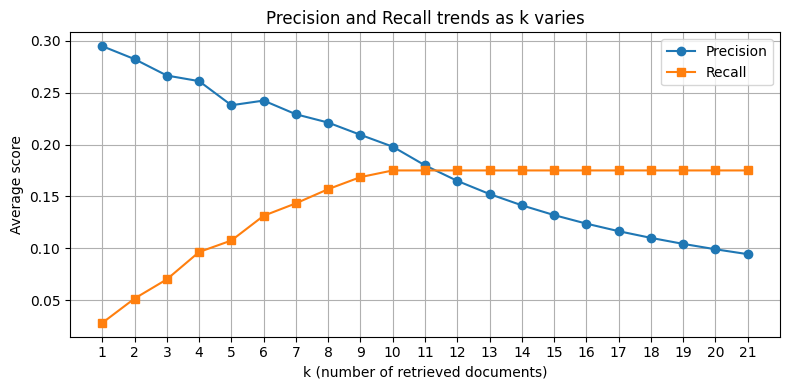

In [64]:
plot_precision_recall(df_queries_bm25, df_qrels_binary, 'Top_BM25_Relevant',k=21)

#### MAP

In [69]:
compute_map_at_k(df_queries_bm25, df_qrels_binary, 'Top_BM25_Relevant', k=5)

np.float64(0.07326792330216293)

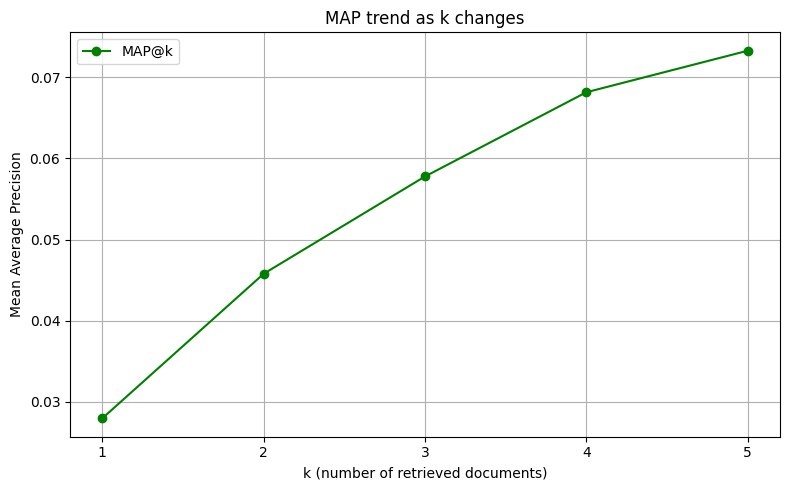

In [70]:
plot_map_curve_iterative(df_queries_bm25, df_qrels_binary, 'Top_BM25_Relevant')

#### nDCG

In [71]:
compute_ndcg_at_k(df_queries_bm25, df_qrels, 'Top_BM25_Relevant')

np.float64(0.4743091577675992)

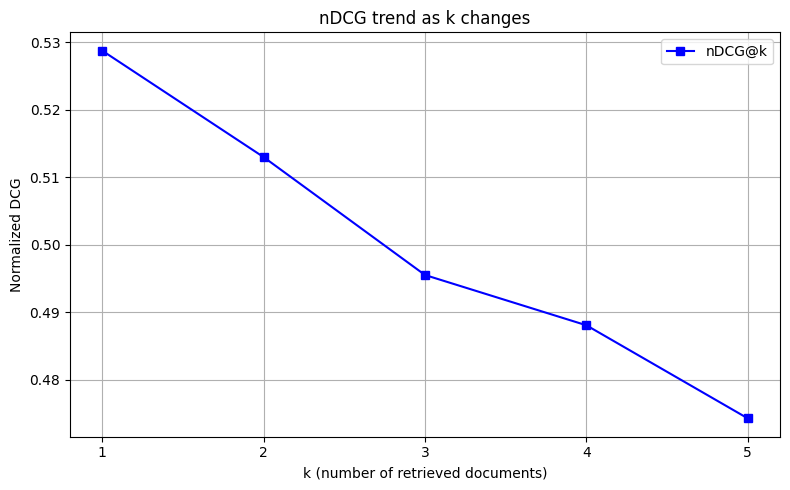

In [72]:
plot_ndcg_curve(df_queries_bm25, df_qrels, 'Top_BM25_Relevant')

### **NEURAL RERANKING**

#### PRECISION and RECALL

In [77]:
compute_precision_recall_at_k(df_queries_biencoder, df_qrels_binary, 'Top10_Biencoder') # k=5

(np.float64(0.42700000000000005), np.float64(0.2144479515815848))

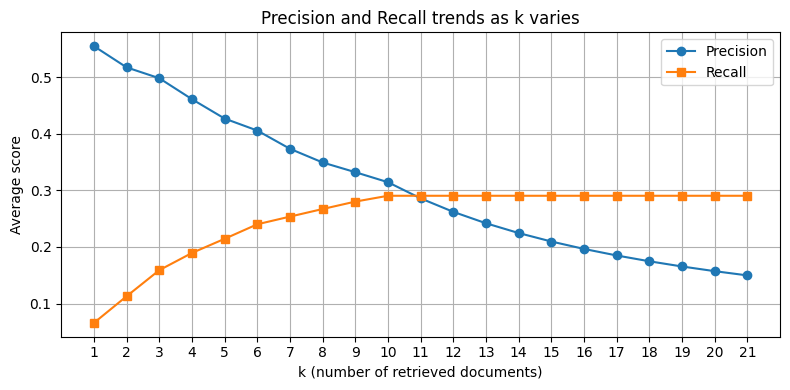

In [78]:
plot_precision_recall(df_queries_biencoder, df_qrels_binary, 'Top10_Biencoder',k=21)

#### MAP

In [79]:
compute_map_at_k(df_queries_biencoder, df_qrels_binary, 'Top10_Biencoder')

np.float64(0.17532454201238992)

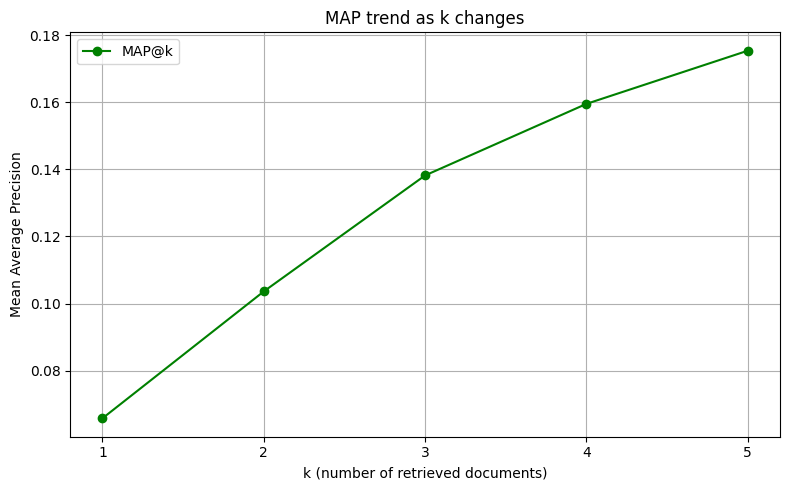

In [81]:
plot_map_curve_iterative(df_queries_biencoder, df_qrels_binary, 'Top10_Biencoder')

#### nDCG

In [82]:
compute_ndcg_at_k(df_queries_biencoder, df_qrels, 'Top10_Biencoder')

np.float64(0.5075238419243082)

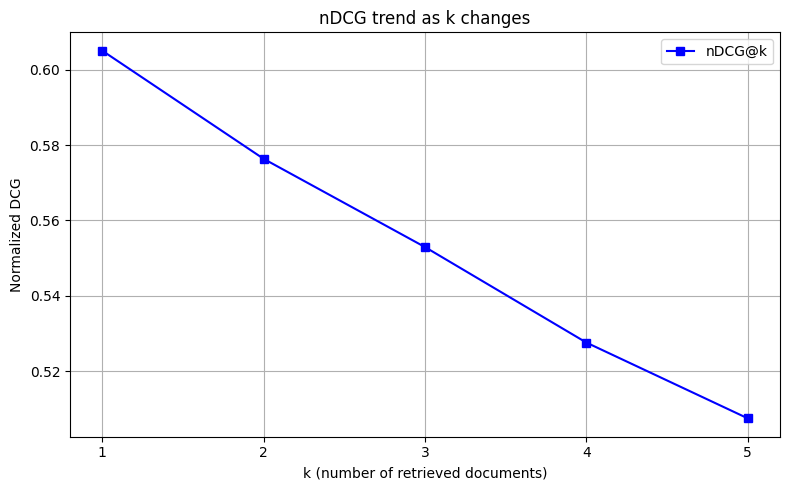

In [83]:
plot_ndcg_curve(df_queries_biencoder, df_qrels, 'Top10_Biencoder')

# **PHASE II**

The goal is to semantically enrich the original queries, making them more detailed and useful for further analysis.
To achieve this, we implemented Google's Gemini 2.0 Flash Lite model. Then:

* We added an empty column to store the expanded versions of the queries.
* We used to send each query to the Gemini model via a prompt, generating a more informative version (up to 150 characters).


Importing Gemini:





```
!pip install google-generativeai
```


```
import google.generativeai as genai
import time

#Initialize Gemini
genai.configure(api_key="api_key")

#Load the model
model = genai.GenerativeModel('gemini-2.0-flash-lite')
```




## ***QUERY EXPANSION***




```
df_queries_expandeded = df_queries.copy()
df_queries_expandeded["query_expanded"] = ""
df_queries_expandeded["query_expanded"] = df_queries_expandeded["query_expanded"].astype("string")
```

```
#Define function to expand a query
def expand_query(query: str) -> str:
    prompt = f"""
     Expand the following query in a more informative way, i only want to see the expanded query, don't add anything else and make it no longer than 150 characters:

    Original: "{query}"
    Expanded:"""
    try:
        response = model.generate_content(prompt)
        return response.text.strip()
    except Exception as e:
        print(f"Error expanding query '{query}': {e}")
        return "ERROR"

# Step 4: Iterate over the DataFrame and fill the empty column
for i, row in df_queries_expandeded.iterrows():
    if not row["query_expanded"]:  # only if empty
        expanded = expand_query(row["text"])
        df_queries_expandeded.at[i, "query_expanded"] = expanded
        time.sleep(1.2)  # optional: delay for rate limit
```




In [85]:
df_queries_expandeded = pd.read_csv('/content/df_queries_expandeded.csv')

In [86]:
df_queries_expandeded.head()

,query_id,text,query_expanded
0,3990512,how can we get concentration onsomething?,How to improve focus/attention? Techniques & s...
1,714612,Why doesn't the water fall off earth if it's ...,Why is water retained on Earth's spherical sha...
2,2528767,How do I determine the charge of the iron ion ...,Determine iron ion charge in ferric chloride (...
3,821387,I have mice.How do I get rid of them humanely?,"""Eradicate mice from my home ethically. Sugges..."
4,1880028,"What does ""see Leaflet"" mean on Ept Pregnancy ...","What does ""see Leaflet"" on an EPT pregnancy te..."


In [87]:
df_queries_expandeded['query_id'] = df_queries_expandeded['query_id'].astype(str)

In [88]:
df_queries_expandeded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   query_id        200 non-null    object
 1   text            200 non-null    object
 2   query_expanded  200 non-null    object
dtypes: object(3)
memory usage: 4.8+ KB


### BASELINE RETRIEVAL (BM25)

In [89]:
df_doc_expanded_special = df_doc_final.copy()
df_doc_expanded_special = df_doc_expanded_special.rename(columns={'text': 'text_tokenization'})

#Tokenize all the queries
df_queries_expandeded_special = df_queries_expandeded.copy()
df_queries_expandeded_special = df_queries_expandeded_special.rename(columns={'query_expanded': 'text_tokenization'})


In [94]:
generate_bm25(df_doc_expanded_special, df_queries_expandeded_special)

,query_id,text,text_tokenization,Top_BM25_Relevant
0,3990512,how can we get concentration onsomething?,How to improve focus/attention? Techniques & s...,"[(2509828_0, 1.0), (1682242_0, 0.9930743174563..."
1,714612,Why doesn't the water fall off earth if it's ...,Why is water retained on Earth's spherical sha...,"[(2006872_1, 1.0), (1922980_3, 0.8919852822867..."
2,2528767,How do I determine the charge of the iron ion ...,Determine iron ion charge in ferric chloride (...,"[(2528767_0, 1.0), (2528767_1, 0.7341555890133..."
3,821387,I have mice.How do I get rid of them humanely?,"""Eradicate mice from my home ethically. Sugges...","[(4064894_6, 1.0), (113971_5, 0.96674732056940..."
4,1880028,"What does ""see Leaflet"" mean on Ept Pregnancy ...","What does ""see Leaflet"" on an EPT pregnancy te...","[(1426716_0, 1.0), (2266582_1, 0.9229037370461..."
...,...,...,...,...
195,2192891,how are braces put on and do they hurt a lot?,"How are orthodontic braces applied, and what i...","[(2192891_6, 1.0), (2322656_1, 0.9620708544809..."
196,4406669,What do you order at Taco Bell?,What are your favorite Taco Bell menu items?,"[(2994485_11, 1.0), (4430763_1, 0.859485232905..."
197,1582877,why do we go to school if in the real world we...,Why is schooling required when real-world appl...,"[(116663_4, 1.0), (3509170_2, 0.91557955472604..."
198,1340574,Why do some people only go to church on Easter...,Why do some attend church only Easter/Christma...,"[(2874491_19, 1.0), (2244209_4, 1.0), (751_8, ..."


### NEURAL RERANKING

In [95]:
df_doc_expanded_biencoder = df_doc_final.copy()

df_queries_expandeded_biencoder = df_queries_expandeded.copy()

In [96]:
df_queries_expandeded_biencoder = df_queries_expandeded_biencoder.drop(columns=['text'])
df_queries_expandeded_biencoder = df_queries_expandeded_biencoder.rename(columns={'query_expanded': 'text'})

In [97]:
df_queries_expandeded_biencoder.head()

,query_id,text
0,3990512,How to improve focus/attention? Techniques & s...
1,714612,Why is water retained on Earth's spherical sha...
2,2528767,Determine iron ion charge in ferric chloride (...
3,821387,"""Eradicate mice from my home ethically. Sugges..."
4,1880028,"What does ""see Leaflet"" on an EPT pregnancy te..."


In [98]:
df_queries_expandeded_biencoder.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   query_id  200 non-null    object
 1   text      200 non-null    object
dtypes: object(2)
memory usage: 3.3+ KB


In [99]:
generate_biencoder(df_doc_expanded_biencoder, df_queries_expandeded_biencoder)

Number of documents: 403666
Number of queries: 200
Starting document encoding...
Document encoding completed.
Document embeddings shape: torch.Size([403666, 384])
Starting query ranking...


Ranking top 10 documents globally per query: 100%|██████████| 200/200 [04:07<00:00,  1.24s/it]

Biencoder completed successfully.


,query_id,text,Top10_Biencoder
0,3990512,How to improve focus/attention? Techniques & s...,"[(3051681_3, 0.7350537), (3077638_1, 0.7050909..."
1,714612,Why is water retained on Earth's spherical sha...,"[(2781942_4, 0.6581563), (714612_7, 0.6453507)..."
2,2528767,Determine iron ion charge in ferric chloride (...,"[(2528767_0, 0.7477005), (2528767_1, 0.7325453..."
3,821387,"""Eradicate mice from my home ethically. Sugges...","[(821387_9, 0.6755525), (2226616_7, 0.6639371)..."
4,1880028,"What does ""see Leaflet"" on an EPT pregnancy te...","[(1880028_0, 0.6505761), (1880028_4, 0.5341641..."
...,...,...,...
195,2192891,"How are orthodontic braces applied, and what i...","[(2192891_1, 0.69302404), (2192891_6, 0.663932..."
196,4406669,What are your favorite Taco Bell menu items?,"[(4406669_21, 0.7835652), (209084_8, 0.7313213..."
197,1582877,Why is schooling required when real-world appl...,"[(1919603_6, 0.6008875), (1582877_5, 0.5770358..."
198,1340574,Why do some attend church only Easter/Christma...,"[(1340574_3, 0.7934241), (1340574_13, 0.770689..."


### EVALUATION METRICS

#### **BM25**

##### PRECISION and RECALL

In [100]:
compute_precision_recall_at_k(df_queries_expandeded_special, df_qrels_binary, 'Top_BM25_Relevant') # k=5

(np.float64(0.15), np.float64(0.08119187723284214))

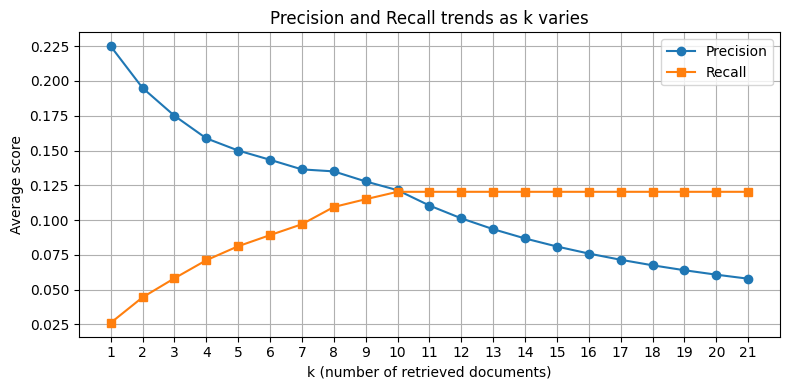

In [101]:
plot_precision_recall(df_queries_expandeded_special, df_qrels_binary, 'Top_BM25_Relevant',k=21)

##### MAP

In [114]:
compute_map_at_k(df_queries_expandeded_special, df_qrels_binary, 'Top_BM25_Relevant')

np.float64(0.05743658336412137)

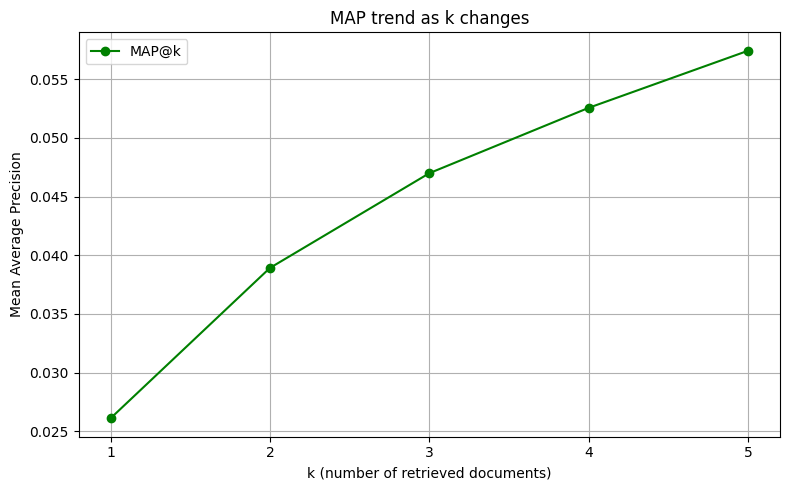

In [115]:
plot_map_curve_iterative(df_queries_expandeded_special, df_qrels_binary, 'Top_BM25_Relevant')

##### nDCG

In [116]:
compute_ndcg_at_k(df_queries_expandeded_special, df_qrels, 'Top_BM25_Relevant')

np.float64(0.23323543427677434)

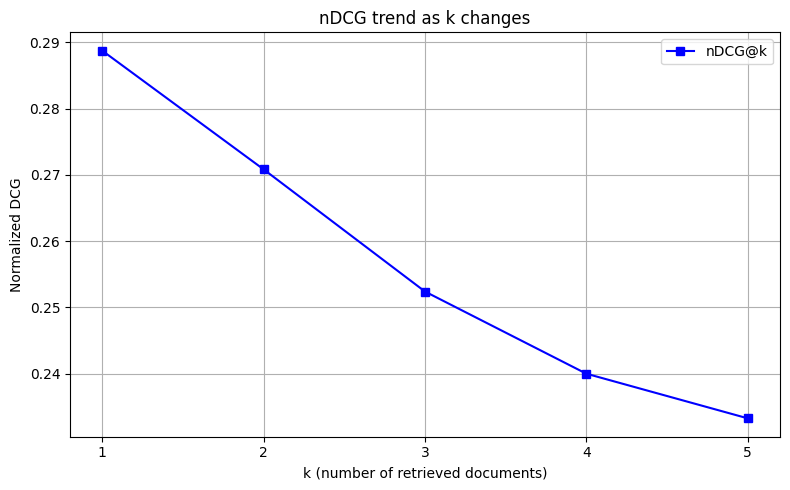

In [117]:
plot_ndcg_curve(df_queries_expandeded_special, df_qrels, 'Top_BM25_Relevant')

#### **NEURAL RERANKING**

##### PRECISION and RECALL

In [118]:
compute_precision_recall_at_k(df_queries_expandeded_biencoder, df_qrels_binary, 'Top10_Biencoder') # k=5

(np.float64(0.36700000000000005), np.float64(0.18771313931584366))

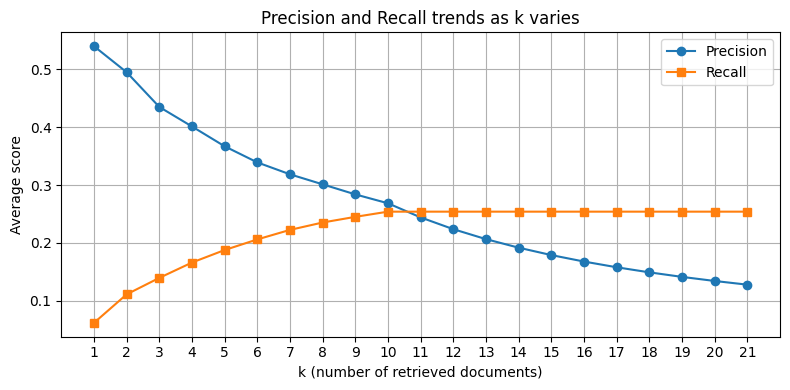

In [119]:
plot_precision_recall(df_queries_expandeded_biencoder, df_qrels_binary, 'Top10_Biencoder', k=21)

##### MAP

In [120]:
compute_map_at_k(df_queries_expandeded_biencoder, df_qrels_binary, 'Top10_Biencoder')

np.float64(0.1563740722425738)

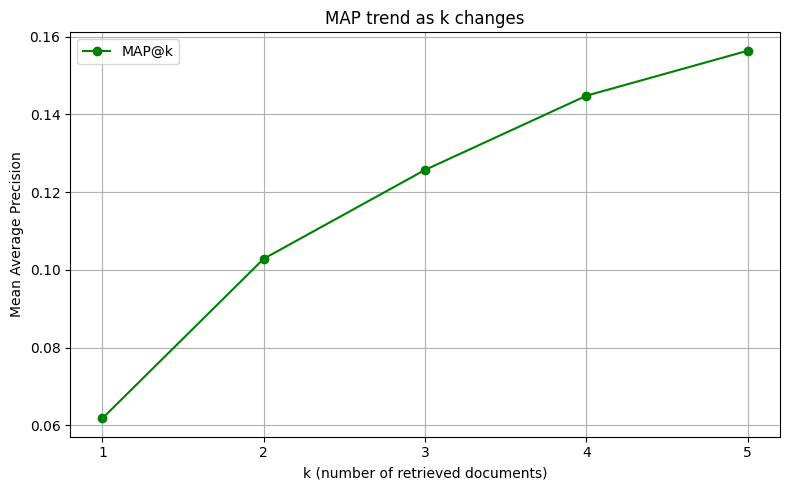

In [121]:
plot_map_curve_iterative(df_queries_expandeded_biencoder, df_qrels_binary, 'Top10_Biencoder')

##### nDCG

In [122]:
compute_ndcg_at_k(df_queries_expandeded_biencoder, df_qrels, 'Top10_Biencoder')

np.float64(0.4352636203255896)

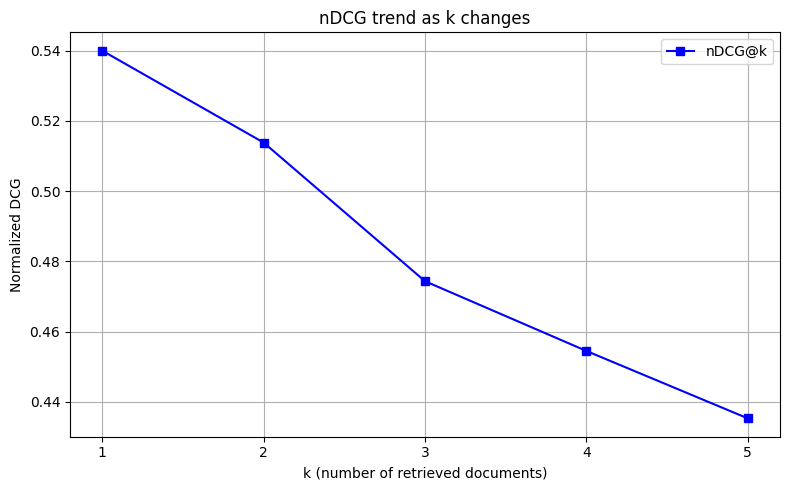

In [123]:
plot_ndcg_curve(df_queries_expandeded_biencoder, df_qrels, 'Top10_Biencoder')

## ***QUERY REFORMULATION: NOVICE***

In this part of the code, the original queries are rewritten to sound like they were written by a novice user.
The Gemini model generates simpler, more naive versions (up to 150 characters), which are saved in a new column of the DataFrame.




```
df_queries_novice = df_queries.copy()
df_queries_novice["query_novice"] = ""
df_queries_novice["query_novice"] = df_queries_novice["query_novice"].astype("string")

```

```
#Define function to make the query sound like a novice wrote it
def expand_query_novice(query: str) -> str:
    prompt = f"""
    Rewrite the following query to make it sound like it was written by a novice, i only want to see the reformulated query, don't add anything else and make it no longer than 150 characters:

    Original: "{query}"
    Expanded:"""
    try:
        response = model.generate_content(prompt)
        return response.text.strip()
    except Exception as e:
        print(f"Error expanding query '{query}': {e}")
        return "ERROR"

# Step 4: Iterate over the DataFrame and fill the empty column
for i, row in df_queries_novice.iterrows():
    if not row["query_novice"]:  # only if empty
        expanded = expand_query_novice(row["text"])
        df_queries_novice.at[i, "query_novice"] = expanded
        time.sleep(1.2)  # optional: delay for rate limit

```



In [124]:
df_queries_novice = pd.read_csv('/content/df_queries_novice.csv')

In [125]:
df_queries_novice.head()

,query_id,text,query_novice
0,3990512,how can we get concentration onsomething?,How do I focus on stuff?
1,714612,Why doesn't the water fall off earth if it's ...,"How come water stays on Earth, even though it'..."
2,2528767,How do I determine the charge of the iron ion ...,How do I figure out the iron thing's charge in...
3,821387,I have mice.How do I get rid of them humanely?,How do I get rid of mice? I don't want to hurt...
4,1880028,"What does ""see Leaflet"" mean on Ept Pregnancy ...","What does the ""see Leaflet"" thing on the pregn..."


In [126]:
df_queries_novice['query_id'] = df_queries_novice['query_id'].astype(str)

In [127]:
df_queries_novice.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   query_id      200 non-null    object
 1   text          200 non-null    object
 2   query_novice  200 non-null    object
dtypes: object(3)
memory usage: 4.8+ KB


### BASELINE RETRIEVAL (BM25)

In [128]:
df_doc_novice_special = df_doc_final.copy()
df_doc_novice_special = df_doc_novice_special.rename(columns={'text': 'text_tokenization'})

#Tokenize all the queries
df_queries_novice_special = df_queries_novice.copy()
df_queries_novice_special = df_queries_novice_special.rename(columns={'query_novice': 'text_tokenization'})

In [129]:
generate_bm25(df_doc_novice_special, df_queries_novice_special)

,query_id,text,text_tokenization,Top_BM25_Relevant
0,3990512,how can we get concentration onsomething?,How do I focus on stuff?,"[(3913709_4, 0.9999999999999999), (1550190_1, ..."
1,714612,Why doesn't the water fall off earth if it's ...,"How come water stays on Earth, even though it'...","[(2483868_0, 1.0), (1986395_14, 0.921950887428..."
2,2528767,How do I determine the charge of the iron ion ...,How do I figure out the iron thing's charge in...,"[(2528767_0, 1.0), (2528767_4, 0.7227771555296..."
3,821387,I have mice.How do I get rid of them humanely?,How do I get rid of mice? I don't want to hurt...,"[(1239473_4, 1.0), (1082990_5, 0.9983012116423..."
4,1880028,"What does ""see Leaflet"" mean on Ept Pregnancy ...","What does the ""see Leaflet"" thing on the pregn...","[(1880028_0, 1.0), (2776567_3, 0.9055986510958..."
...,...,...,...,...
195,2192891,how are braces put on and do they hurt a lot?,How do they put on the metal things on your te...,"[(655285_0, 1.0), (324409_0, 0.948329124067666..."
196,4406669,What do you order at Taco Bell?,What's good to get at Taco Bell? Gimme ideas!,"[(4321206_5, 1.0), (4430763_1, 0.9876871557506..."
197,1582877,why do we go to school if in the real world we...,Why do we learn stuff at school? I don't use i...,"[(1900621_2, 1.0), (1582877_16, 0.993004918140..."
198,1340574,Why do some people only go to church on Easter...,Why do some folks only go to church on Easter?...,"[(477389_2, 1.0), (654975_3, 0.895087631153486..."


### NEURAL RERANKING

In [130]:
df_doc_novice_biencoder = df_doc_final.copy()
df_queries_novice_biencoder = df_queries_novice.copy()

In [131]:
df_queries_novice_biencoder = df_queries_novice_biencoder.drop(columns=['text'])
df_queries_novice_biencoder = df_queries_novice_biencoder.rename(columns={'query_novice': 'text'})

In [132]:
df_queries_novice_biencoder.head()

,query_id,text
0,3990512,How do I focus on stuff?
1,714612,"How come water stays on Earth, even though it'..."
2,2528767,How do I figure out the iron thing's charge in...
3,821387,How do I get rid of mice? I don't want to hurt...
4,1880028,"What does the ""see Leaflet"" thing on the pregn..."


In [133]:
df_queries_novice_biencoder.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   query_id  200 non-null    object
 1   text      200 non-null    object
dtypes: object(2)
memory usage: 3.3+ KB


In [134]:
generate_biencoder(df_doc_novice_biencoder, df_queries_novice_biencoder)

Number of documents: 403666
Number of queries: 200
Starting document encoding...
Document encoding completed.
Document embeddings shape: torch.Size([403666, 384])
Starting query ranking...


Ranking top 10 documents globally per query: 100%|██████████| 200/200 [05:25<00:00,  1.63s/it]

Biencoder completed successfully.


,query_id,text,Top10_Biencoder
0,3990512,How do I focus on stuff?,"[(1561766_5, 0.750554), (3077638_1, 0.726328),..."
1,714612,"How come water stays on Earth, even though it'...","[(2781942_4, 0.676667), (714612_7, 0.6671438),..."
2,2528767,How do I figure out the iron thing's charge in...,"[(2528767_3, 0.6789521), (2528767_4, 0.6763339..."
3,821387,How do I get rid of mice? I don't want to hurt...,"[(1082990_5, 0.75739986), (821387_9, 0.7487687..."
4,1880028,"What does the ""see Leaflet"" thing on the pregn...","[(1880028_0, 0.6302482), (1880028_3, 0.5969472..."
...,...,...,...
195,2192891,How do they put on the metal things on your te...,"[(2192891_3, 0.7174017), (655285_1, 0.67302316..."
196,4406669,What's good to get at Taco Bell? Gimme ideas!,"[(298001_7, 0.75615954), (9560_3, 0.7399299), ..."
197,1582877,Why do we learn stuff at school? I don't use i...,"[(1582877_16, 0.76967776), (1425270_0, 0.68717..."
198,1340574,Why do some folks only go to church on Easter?...,"[(1340574_3, 0.77948064), (1340574_13, 0.76627..."


### EVALUATION METRICS

#### **BM25**

##### PRECISION and RECALL

In [135]:
compute_precision_recall_at_k(df_queries_novice_special, df_qrels_binary, 'Top_BM25_Relevant') # k=5

(np.float64(0.11200000000000002), np.float64(0.05062653126821244))

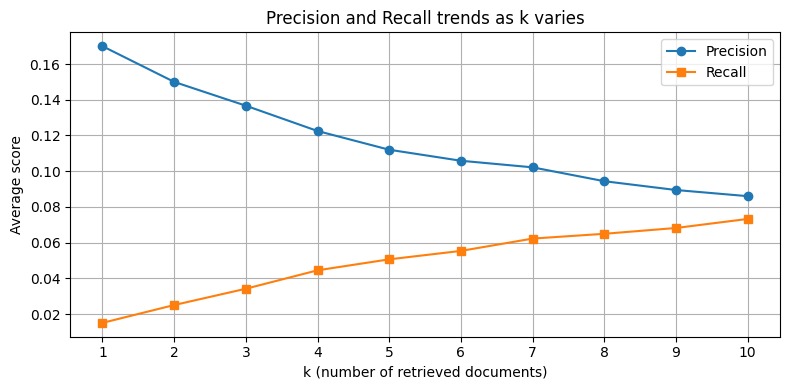

In [136]:
plot_precision_recall(df_queries_novice_special, df_qrels_binary, 'Top_BM25_Relevant')

##### MAP

In [137]:
compute_map_at_k(df_queries_novice_special, df_qrels_binary, 'Top_BM25_Relevant')

np.float64(0.035160672939762654)

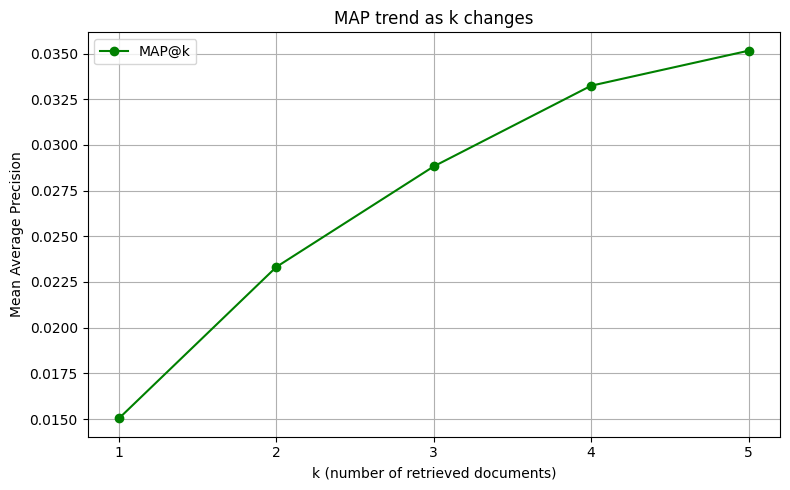

In [138]:
plot_map_curve_iterative(df_queries_novice_special, df_qrels_binary, 'Top_BM25_Relevant')

##### nDCG

In [139]:
compute_ndcg_at_k(df_queries_novice_special, df_qrels, 'Top_BM25_Relevant')

np.float64(0.1857318731162998)

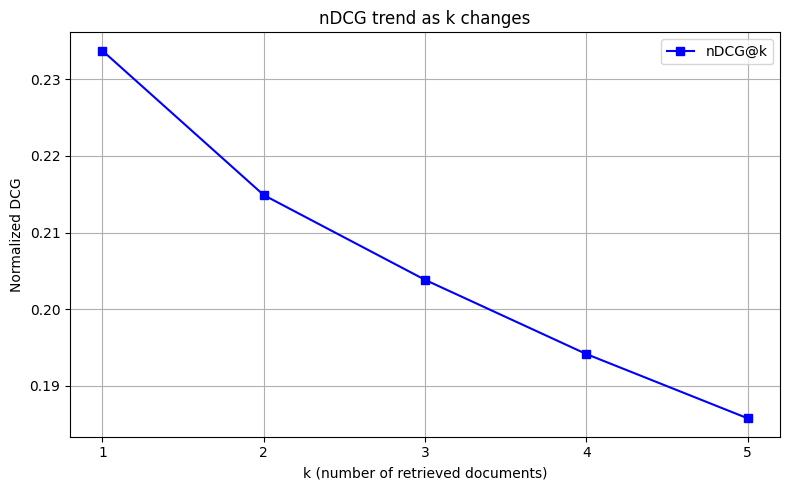

In [140]:
plot_ndcg_curve(df_queries_novice_special, df_qrels, 'Top_BM25_Relevant')

#### **NEURAL RERANKING**

##### PRECISION and RECALL

In [141]:
compute_precision_recall_at_k(df_queries_novice_biencoder, df_qrels_binary, 'Top10_Biencoder') # k=5

(np.float64(0.26400000000000007), np.float64(0.13283356023455176))

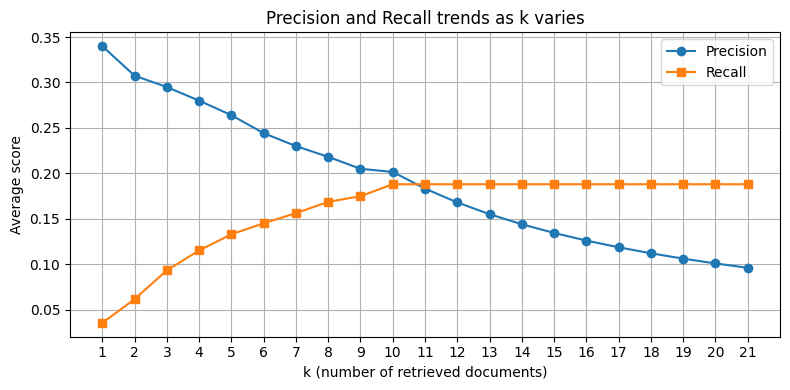

In [142]:
plot_precision_recall(df_queries_novice_biencoder, df_qrels_binary, 'Top10_Biencoder', k=21)

##### MAP

In [143]:
compute_map_at_k(df_queries_novice_biencoder, df_qrels_binary, 'Top10_Biencoder')

np.float64(0.09655920161682001)

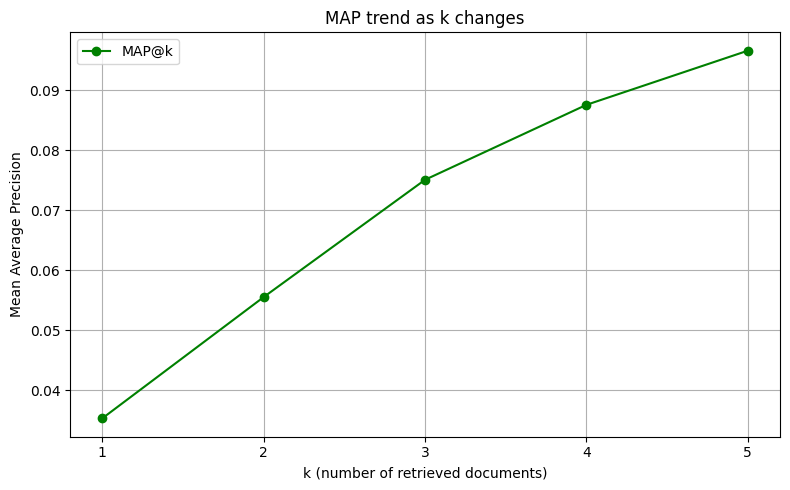

In [144]:
plot_map_curve_iterative(df_queries_novice_biencoder, df_qrels_binary, 'Top10_Biencoder')

##### nDCG

In [145]:
compute_ndcg_at_k(df_queries_novice_biencoder, df_qrels, 'Top10_Biencoder')

np.float64(0.31921597164166476)

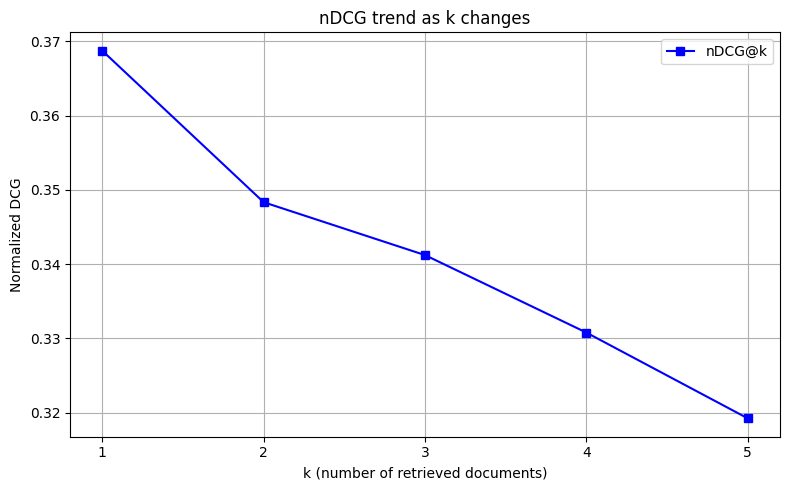

In [146]:
plot_ndcg_curve(df_queries_novice_biencoder, df_qrels, 'Top10_Biencoder')

## ***QUERY REFORMULATION: EXPERT***

In this section, the original queries are reformulated to sound as if written by an expert.
The Gemini model generates more precise and technical versions (up to 150 characters), which are stored in a new column of the DataFrame.



```
df_queries_expert = df_queries.copy()
df_queries_expert["query_expert"] = ""
df_queries_expert["query_expert"] = df_queries_expert["query_expert"].astype("string")
```

```
#Define function to make the query sound like a expert wrote it
def expand_query_expert(query: str) -> str:
    prompt = f"""
    Rewrite the following query to make it sound like it was written by an expert, i only want to see the reformulated query, don't add anything else and make it no longer than 150 characters:

    Original: "{query}"
    Expanded:"""
    try:
        response = model.generate_content(prompt)
        return response.text.strip()
    except Exception as e:
        print(f"Error expanding query '{query}': {e}")
        return "ERROR"

# Step 4: Iterate over the DataFrame and fill the empty column
for i, row in df_queries_expert.iterrows():
    if not row["query_expert"]:  # only if empty
        expanded = expand_query_expert(row["text"])
        df_queries_expert.at[i, "query_expert"] = expanded
        time.sleep(1.2)  # optional: delay for rate limit

```



In [158]:
df_queries_expert = pd.read_csv('/content/df_queries_expert.csv')

In [148]:
df_queries_expert.head()

,query_id,text,query_expert
0,3990512,how can we get concentration onsomething?,How to enhance cognitive focus and sustained a...
1,714612,Why doesn't the water fall off earth if it's ...,"Considering Earth's spheroidal geometry, expla..."
2,2528767,How do I determine the charge of the iron ion ...,Determine iron's oxidation state in FeCl3.
3,821387,I have mice.How do I get rid of them humanely?,Implement humane rodent control strategies.
4,1880028,"What does ""see Leaflet"" mean on Ept Pregnancy ...","Interpreting ""see Leaflet"" on an EPT pregnancy..."


In [149]:
df_queries_expert['query_id'] = df_queries_expert['query_id'].astype(str)

In [150]:
df_queries_expert.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   query_id      200 non-null    object
 1   text          200 non-null    object
 2   query_expert  200 non-null    object
dtypes: object(3)
memory usage: 4.8+ KB


### BASELINE RETRIEVAL (BM25)

In [151]:
df_doc_expert_special = df_doc_final.copy()
df_doc_expert_special = df_doc_expert_special.rename(columns={'text': 'text_tokenization'})

#Tokenize all the queries
df_queries_expert_special = df_queries_expert.copy()
df_queries_expert_special = df_queries_expert_special.rename(columns={'query_expert': 'text_tokenization'})

In [152]:
generate_bm25(df_doc_expert_special, df_queries_expert_special)

,query_id,text,text_tokenization,Top_BM25_Relevant
0,3990512,how can we get concentration onsomething?,How to enhance cognitive focus and sustained a...,"[(3616936_31, 1.0), (870696_4, 0.9066268736129..."
1,714612,Why doesn't the water fall off earth if it's ...,"Considering Earth's spheroidal geometry, expla...","[(2781942_4, 1.0), (714612_7, 0.93862939070083..."
2,2528767,How do I determine the charge of the iron ion ...,Determine iron's oxidation state in FeCl3.,"[(2781578_0, 1.0), (2528767_0, 0.8500826006359..."
3,821387,I have mice.How do I get rid of them humanely?,Implement humane rodent control strategies.,"[(1082990_8, 1.0), (990705_2, 0.96360123028508..."
4,1880028,"What does ""see Leaflet"" mean on Ept Pregnancy ...","Interpreting ""see Leaflet"" on an EPT pregnancy...","[(1426716_0, 1.0), (2266582_1, 0.9229037370461..."
...,...,...,...,...
195,2192891,how are braces put on and do they hurt a lot?,Initiation of orthodontic bracket placement pr...,"[(3817275_0, 1.0), (2435120_19, 0.969153501900..."
196,4406669,What do you order at Taco Bell?,What are your preferred Taco Bell menu selecti...,"[(4430763_1, 0.9999999999999999), (2008738_6, ..."
197,1582877,why do we go to school if in the real world we...,Considering the practical application discrepa...,"[(576132_6, 1.0), (1164414_4, 0.96031269668928..."
198,1340574,Why do some people only go to church on Easter...,"""Elucidate the motivations behind infrequent r...","[(1657443_6, 1.0), (29866_3, 0.933230234175577..."


### NEURAL RERANKING

In [153]:
df_doc_expert_biencoder = df_doc_final.copy()
df_queries_expert_biencoder = df_queries_expert.copy()

In [154]:
df_queries_expert_biencoder = df_queries_expert_biencoder.drop(columns=['text'])
df_queries_expert_biencoder = df_queries_expert_biencoder.rename(columns={'query_expert': 'text'})

In [155]:
df_queries_expert_biencoder.head()

,query_id,text
0,3990512,How to enhance cognitive focus and sustained a...
1,714612,"Considering Earth's spheroidal geometry, expla..."
2,2528767,Determine iron's oxidation state in FeCl3.
3,821387,Implement humane rodent control strategies.
4,1880028,"Interpreting ""see Leaflet"" on an EPT pregnancy..."


In [156]:
df_queries_expert_biencoder.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   query_id  200 non-null    object
 1   text      200 non-null    object
dtypes: object(2)
memory usage: 3.3+ KB


In [159]:
generate_biencoder(df_doc_expert_biencoder, df_queries_expert_biencoder)

Number of documents: 403666
Number of queries: 200
Starting document encoding...
Document encoding completed.
Document embeddings shape: torch.Size([403666, 384])
Starting query ranking...


Ranking top 10 documents globally per query: 100%|██████████| 200/200 [04:04<00:00,  1.22s/it]

Biencoder completed successfully.


,query_id,text,Top10_Biencoder
0,3990512,How to enhance cognitive focus and sustained a...,"[(870696_4, 0.6778571), (3313750_14, 0.6024774..."
1,714612,"Considering Earth's spheroidal geometry, expla...","[(1337892_4, 0.71147466), (2781942_4, 0.624917..."
2,2528767,Determine iron's oxidation state in FeCl3.,"[(2528767_0, 0.6921736), (2528767_4, 0.682478)..."
3,821387,Implement humane rodent control strategies.,"[(3474558_1, 0.6681277), (3474558_4, 0.6605053..."
4,1880028,"Interpreting ""see Leaflet"" on an EPT pregnancy...","[(1880028_0, 0.5605852), (2546325_4, 0.4700882..."
...,...,...,...
195,2192891,Initiation of orthodontic bracket placement pr...,"[(2192891_1, 0.6114865), (2192891_6, 0.6097223..."
196,4406669,What are your preferred Taco Bell menu selecti...,"[(4406669_21, 0.76328206), (2994485_11, 0.6574..."
197,1582877,Considering the practical application discrepa...,"[(700895_1, 0.7200707), (713206_2, 0.53193897)..."
198,1340574,"""Elucidate the motivations behind infrequent r...","[(1657443_6, 0.6686573), (2033670_2, 0.6536215..."


### EVALUATION METRICS

#### **BM25**

##### PRECISION and RECALL

In [160]:
compute_precision_recall_at_k(df_queries_expert_special, df_qrels_binary, 'Top_BM25_Relevant') #k=5

(np.float64(0.10300000000000001), np.float64(0.055208181686025475))

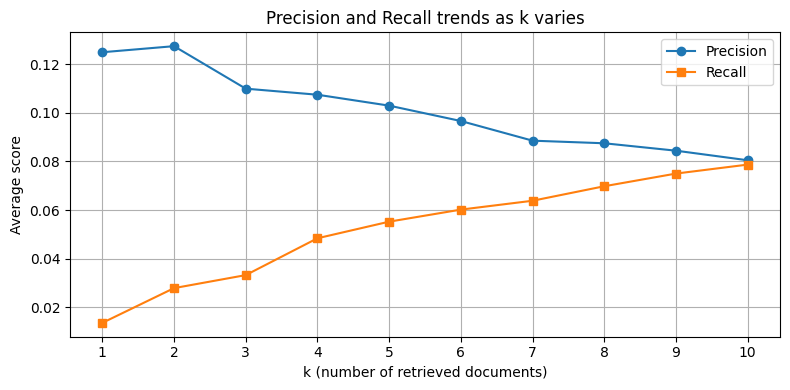

In [161]:
plot_precision_recall(df_queries_expert_special, df_qrels_binary, 'Top_BM25_Relevant')

##### MAP

In [162]:
compute_map_at_k(df_queries_expert_special, df_qrels_binary, 'Top_BM25_Relevant')

np.float64(0.036777632109139466)

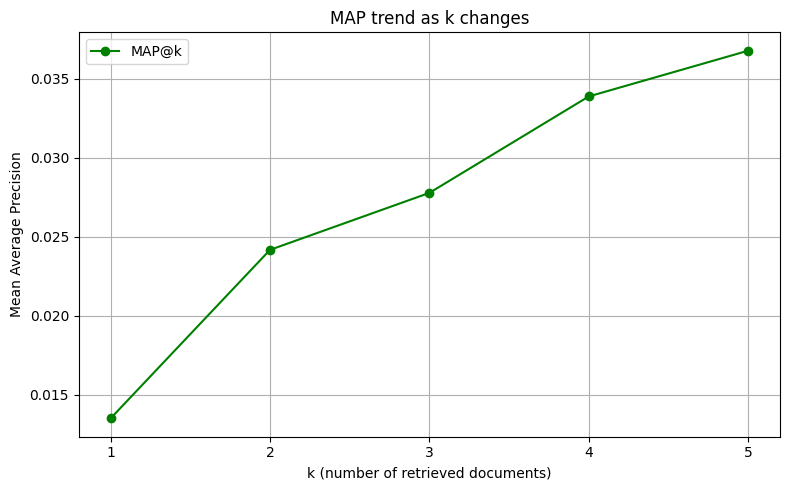

In [163]:
plot_map_curve_iterative(df_queries_expert_special, df_qrels_binary, 'Top_BM25_Relevant')

##### nDCG

In [164]:
compute_ndcg_at_k(df_queries_expert_special, df_qrels, 'Top_BM25_Relevant')

np.float64(0.17371188818967923)

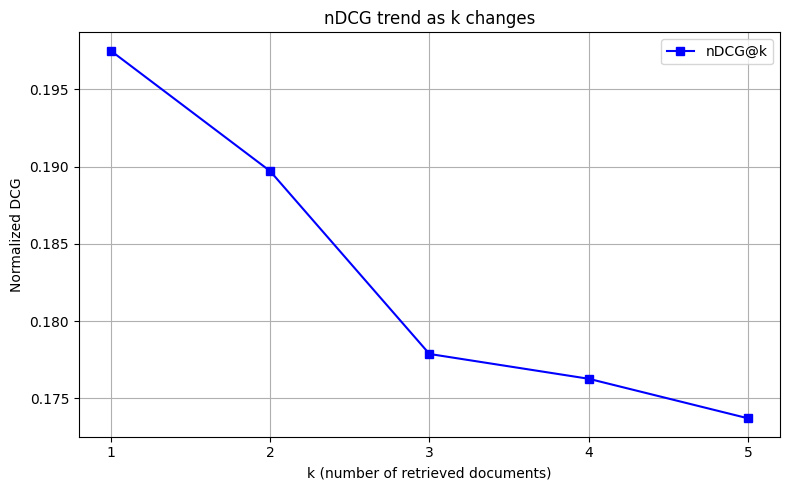

In [165]:
plot_ndcg_curve(df_queries_expert_special, df_qrels, 'Top_BM25_Relevant')

#### **NEURAL RERANKING**

##### PRECISION and RECALL

In [166]:
compute_precision_recall_at_k(df_queries_expert_biencoder, df_qrels_binary, 'Top10_Biencoder') # k=5

(np.float64(0.29600000000000004), np.float64(0.15882657313206155))

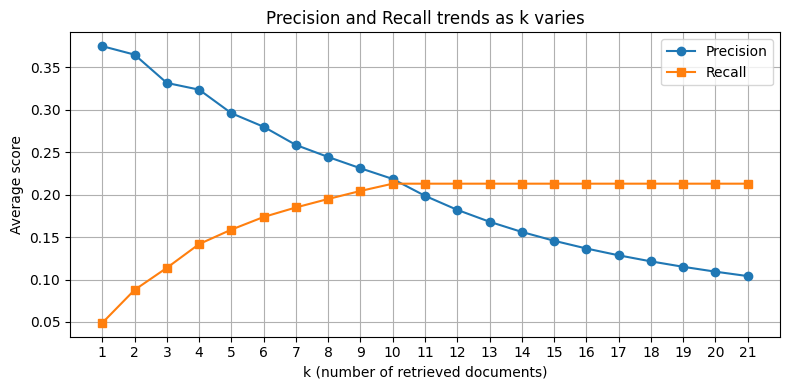

In [167]:
plot_precision_recall(df_queries_expert_biencoder, df_qrels_binary, 'Top10_Biencoder', k=21)

##### MAP

In [168]:
compute_map_at_k(df_queries_expert_biencoder, df_qrels_binary, 'Top10_Biencoder')

np.float64(0.12526956919634805)

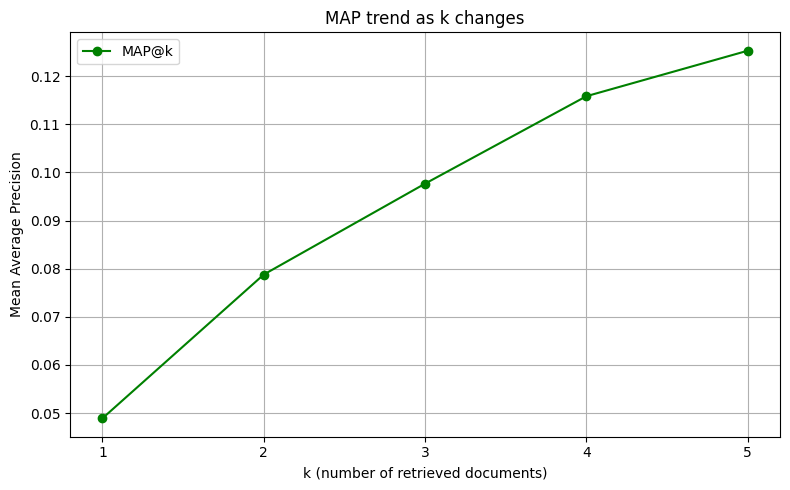

In [169]:
plot_map_curve_iterative(df_queries_expert_biencoder, df_qrels_binary, 'Top10_Biencoder')

##### nDCG

In [170]:
compute_ndcg_at_k(df_queries_expert_biencoder, df_qrels, 'Top10_Biencoder')

np.float64(0.3465391264264086)

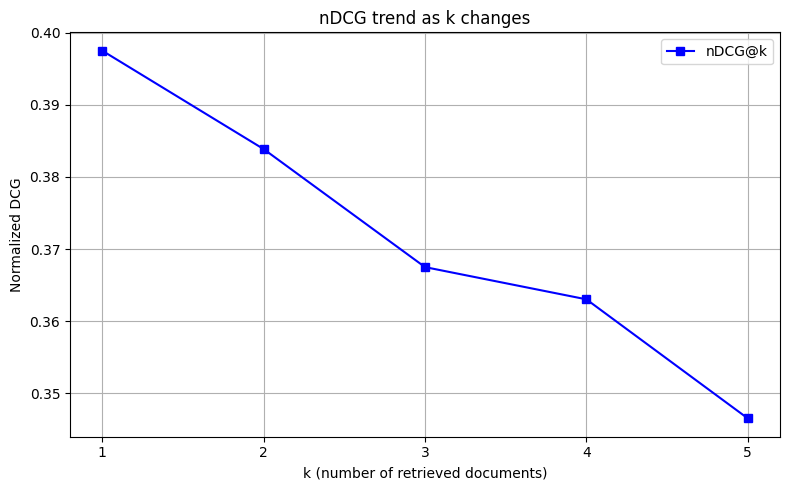

In [171]:
plot_ndcg_curve(df_queries_expert_biencoder, df_qrels, 'Top10_Biencoder')

# **FINAL**

In this final step, all the previously generated query versions are merged into a single DataFrame.
The original DataFrame is joined with the expanded, novice-style, and expert-style queries using the query_id as the key. This results in a unified structure containing all variations for each query.

In [178]:
df_queries_final = df_queries.copy()

In [179]:
df_queries_final['query_id'] = df_queries_final['query_id'].astype(str)

In [180]:
#Merge df_queries_expandeded into df_query_final
df_queries_final = pd.merge(df_queries_final, df_queries_expandeded[['query_id', 'query_expanded']], on='query_id', how='left')

#Merge df_queries_novice into df_query_final
df_queries_final = pd.merge(df_queries_final, df_queries_novice[['query_id', 'query_novice']], on='query_id', how='left')

#Merge df_queries_expert into df_query_final
df_queries_final = pd.merge(df_queries_final, df_queries_expert[['query_id', 'query_expert']], on='query_id', how='left')

In [181]:
df_queries_final.head()

,query_id,text,query_expanded,query_novice,query_expert
0,3990512,how can we get concentration onsomething?,How to improve focus/attention? Techniques & s...,How do I focus on stuff?,How to enhance cognitive focus and sustained a...
1,714612,Why doesn't the water fall off earth if it's ...,Why is water retained on Earth's spherical sha...,"How come water stays on Earth, even though it'...","Considering Earth's spheroidal geometry, expla..."
2,2528767,How do I determine the charge of the iron ion ...,Determine iron ion charge in ferric chloride (...,How do I figure out the iron thing's charge in...,Determine iron's oxidation state in FeCl3.
3,821387,I have mice.How do I get rid of them humanely?,"""Eradicate mice from my home ethically. Sugges...",How do I get rid of mice? I don't want to hurt...,Implement humane rodent control strategies.
4,1880028,"What does ""see Leaflet"" mean on Ept Pregnancy ...","What does ""see Leaflet"" on an EPT pregnancy te...","What does the ""see Leaflet"" thing on the pregn...","Interpreting ""see Leaflet"" on an EPT pregnancy..."
